EMPLOYEE CHURN PREDICTION

1.1 IMPORTING THE LIBRARIES

In [1]:
from google.colab import files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings(action='ignore')

1.2 UPLOADING THE FILE IN THE COLAB

In [2]:
# 1 upload csv file
print("Upload Your Csv File:")
uploaded=files.upload()

# 2 load it
filename=list(uploaded.keys())[0]
df=pd.read_csv(filename)
print('preview:')

Upload Your Csv File:


Saving customer_churn_data.csv to customer_churn_data.csv
preview:


1.3 TOP 5 EMPLOYEES

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,CUST0000,Male,0,No,Yes,23,No,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer,49.85,1146.55,No
1,CUST0001,Female,0,Yes,No,43,No,No phone service,DSL,Yes,...,Yes,No,Yes,No,Month-to-month,No,Mailed check,100.70,4330.10,Yes
2,CUST0002,Male,1,No,No,51,Yes,No,DSL,No,...,Yes,Yes,No,No,One year,No,Electronic check,97.33,4963.83,Yes
3,CUST0003,Male,1,No,No,72,Yes,Yes,DSL,Yes,...,Yes,No,No,No,Month-to-month,No,Credit card,101.38,7299.36,No
4,CUST0004,Male,1,No,No,25,Yes,Yes,DSL,No,...,No,Yes,No,Yes,Month-to-month,No,Electronic check,52.22,1305.50,Yes


1.4 DATA TYPES OF THE COLUMNS

In [4]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


2. HANDLING THE MISSING VALUES

2.1 FINDING THE MISSING VALUES

In [5]:
df.isna().mean()*100

,0
customerID,0.0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0


2.2 DESCRIBING THE MEAN , MEDIAN , STANDARD DEVIATION

In [6]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,5880,5880,5880.000000,5880,5880,5880.000000,5880,5880,5880,5880,...,5880,5880,5880,5880,5880,5880,5880,5880.000000,5880.000000,5880
unique,5880,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,NaN,2
top,CUST5879,Male,NaN,Yes,No,NaN,Yes,No phone service,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Credit card,NaN,NaN,No
freq,1,2950,NaN,2995,3004,NaN,2941,2939,2029,2029,...,2029,2029,2029,2029,2020,2990,1503,NaN,NaN,2982
mean,NaN,NaN,0.500680,NaN,NaN,36.549150,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.157779,2566.813165,NaN
std,NaN,NaN,0.500042,NaN,NaN,20.909674,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.804615,1910.017743,NaN
min,NaN,NaN,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000,20.030000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.717500,1020.217500,NaN
50%,NaN,NaN,1.000000,NaN,NaN,37.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.155000,2136.445000,NaN
75%,NaN,NaN,1.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,95.457500,3767.665000,NaN


In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

3. EXPLORATORY DATA ANALYSIS

3.1 CHURN ANALYSIS

<Axes: ylabel='count'>

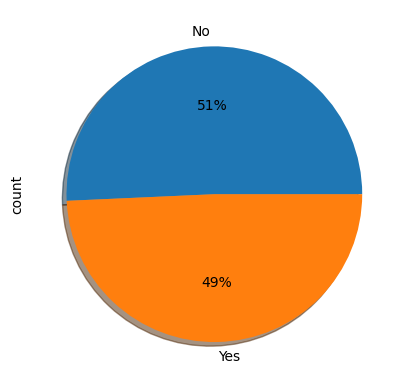

In [8]:
df['Churn'].value_counts().plot(kind='pie',autopct='%2.0f%%',shadow=True)

3.2 BAR PLOT OF CHURN ANALYSIS

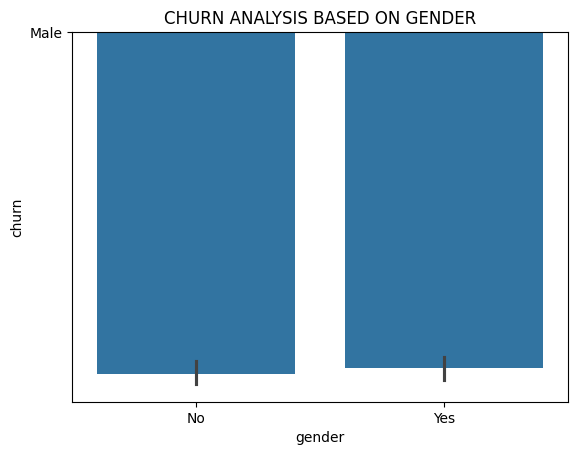

In [9]:
sns.barplot(x='Churn',y='gender',data=df)
plt.xlabel('gender')
plt.ylabel('churn')
plt.title('CHURN ANALYSIS BASED ON GENDER')
plt.show()

3.3 CHURN BASED ON CONTRACT

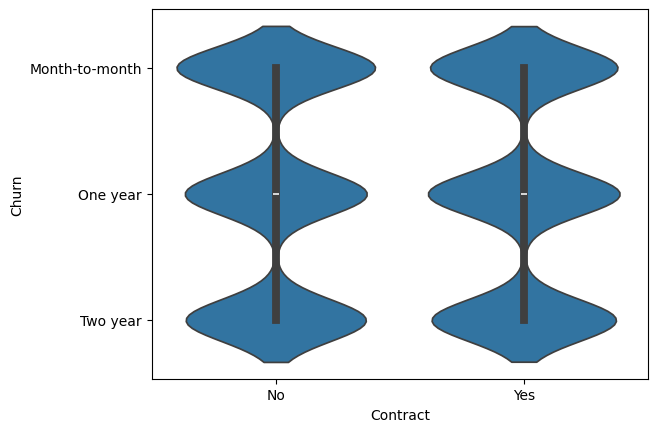

In [10]:
sns.violinplot(x='Churn',y='Contract',data=df)
plt.xlabel('Contract')
plt.ylabel('Churn')
plt.show()

3.4 CORRELATION OF ALL NUMERIC VALUES IN DATA FRAME

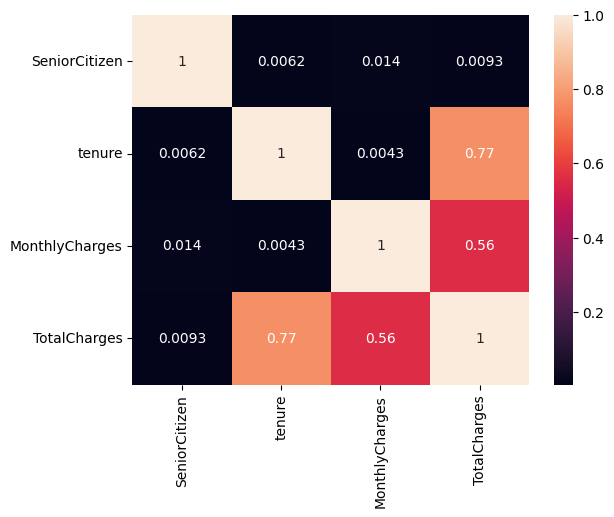

In [12]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

3.5 CHURN ANALYSIS BASED ON CONTRACT

<Axes: xlabel='SeniorCitizen', ylabel='Churn'>

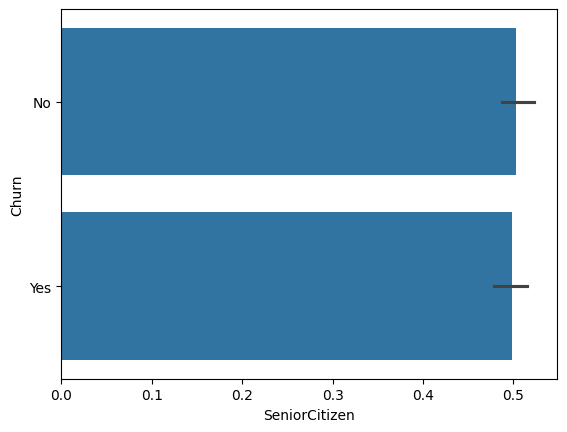

In [13]:
sns.barplot(x='SeniorCitizen',y='Churn',data=df)